# Problem 2 — Transformer experiments and comparison with Problem 1

**Student ID:** 2026AK05702  
**Name :** POOJA MUDULI


**Model width:** 128 · **Heads:** 4 · **Seeds:** 42, 123, 2026

This notebook contains the implemented attention components, tests, HAR Transformer experiments, Tiny Shakespeare language modeling, ablations, figures, and a comparison against the **actual Problem 1 HAR results** supplied separately as `results.csv`. The nine original Problem 1 HAR rows are embedded below so the comparison runs without uploading or rerunning the Problem 1 notebook. Run all cells in Google Colab with a GPU runtime; full training can take time. The notebook is not a substitute for the separately required assignment report or accurate academic-integrity disclosure.


In [1]:
import time
notebook_start = time.perf_counter()

In [2]:
# Initialize libraries, settings, output paths and reproducibility
import os, math, random, time, urllib.request, zipfile, copy, csv
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
D=128; HEADS=4; SEEDS=[42,123,2026]; BATCH_SIZE=64; HAR_EPOCHS=8
LM_EPOCHS=1; LM_STEPS=1000; LM_BATCH=32; LM_CONTEXT=128; LM_LAYERS=4
ROOT=Path('problem2'); FIG=ROOT/'figures'; FIG.mkdir(parents=True,exist_ok=True)
COLUMNS=['problem','model','seed','seq_len','test_acc','macro_f1','test_mse','params','sec_per_epoch','val_loss_nats','bits_per_char','notes']
RESULTS=Path('results.csv')
def set_seed(seed):
 random.seed(seed);np.random.seed(seed);torch.manual_seed(seed)
 if torch.cuda.is_available():torch.cuda.manual_seed_all(seed)
def record(**kwargs):
 row={k:kwargs.get(k,None) for k in COLUMNS}
 old=pd.read_csv(RESULTS) if RESULTS.exists() else pd.DataFrame(columns=COLUMNS)
 key=['problem','model','seed','seq_len','notes']
 old=old.loc[~(old[key].fillna('').astype(str)==pd.Series(row)[key].fillna('').astype(str)).all(axis=1)]
 pd.concat([old,pd.DataFrame([row])],ignore_index=True).to_csv(RESULTS,index=False)
def params(model):return sum(p.numel() for p in model.parameters())
set_seed(SEEDS[0]);print('Device:',DEVICE,'PyTorch:',torch.__version__)
assert D%HEADS==0

Device: cuda PyTorch: 2.14.1+cu130


## Task 1 — Scaled attention and hand-worked 3-token example

Choose three 2D tokens with `Q=K=V=[[1,0],[0,1],[1,0]]`. With scale `sqrt(2)`, logits are `Q @ K.T / sqrt(2)` and attention is the row-wise softmax. For rows 1 and 3, unnormalised weights are `(exp(1/sqrt(2)),1,exp(1/sqrt(2)))`; for row 2 they are `(1,exp(1/sqrt(2)),1)`. Therefore rows 1 and 3 output `(2a/(2a+1),1/(2a+1))` and row 2 outputs `(2/(2+a),a/(2+a))`, where `a=exp(1/sqrt(2))`. These values constitute the hand calculation to include in the report.

In [3]:
# Verify the numerical hand calculation independently using PyTorch
q=torch.tensor([[[1.,0.],[0.,1.],[1.,0.]]],device=DEVICE)
a=math.exp(1/math.sqrt(2))
manual=torch.tensor([[[2*a/(2*a+1),1/(2*a+1)],[2/(2+a),a/(2+a)],[2*a/(2*a+1),1/(2*a+1)]]],device=DEVICE)
reference=F.scaled_dot_product_attention(q,q,q)
assert torch.allclose(manual,reference,atol=1e-6)
print('Hand-calculated output:',manual.cpu().numpy().round(6))

Hand-calculated output: [[[0.802224 0.197776]
  [0.49651  0.50349 ]
  [0.802224 0.197776]]]


## Tasks 1–2 — Implemented attention and Transformer components

The next cell implements scaled dot-product attention with masking, multi-head Q/K/V/O projections, pre-LayerNorm encoder blocks, residual connections, width-4d feed-forward layers, dropout, and sinusoidal positional encoding. The following cell checks attention normalization, PyTorch equivalence, causal masking, hand-worked example, tensor shapes, and parameter counts. Review the implementations and acknowledge any AI assistance as required by your course.


In [4]:
# Explicit tensor implementation of attention and Transformer building blocks.
# Review and understand each operation; disclose assistance as required by the course.
def scaled_attention(q, k, v, mask=None):
    scale = math.sqrt(q.size(-1))
    scores = (q @ k.transpose(-2, -1)) / scale
    if mask is not None:
        if mask.dtype == torch.bool:
            scores = scores.masked_fill(~mask, torch.finfo(scores.dtype).min)
        else:
            scores = scores + mask
    weights = torch.softmax(scores, dim=-1)
    return weights @ v, weights

class MyMultiHeadAttention(nn.Module):
    def __init__(self, d, heads, dropout=0.1):
        super().__init__()
        assert d % heads == 0
        self.d, self.heads, self.dk = d, heads, d // heads
        self.q_proj = nn.Linear(d, d)
        self.k_proj = nn.Linear(d, d)
        self.v_proj = nn.Linear(d, d)
        self.out_proj = nn.Linear(d, d)
        self.dropout = nn.Dropout(dropout)

    def split(self, x):
        b, t, _ = x.shape
        return x.reshape(b, t, self.heads, self.dk).transpose(1, 2)

    def forward(self, x, mask=None):
        b, t, _ = x.shape
        q = self.split(self.q_proj(x))
        k = self.split(self.k_proj(x))
        v = self.split(self.v_proj(x))
        # Dropout is applied to the attention output; returned weights remain normalized.
        values, weights = scaled_attention(q, k, v, mask)
        values = values.transpose(1, 2).contiguous().reshape(b, t, self.d)
        return self.out_proj(self.dropout(values)), weights

class MyEncoderBlock(nn.Module):
    def __init__(self, d, heads, dropout=0.1):
        super().__init__()
        self.ln1 = nn.LayerNorm(d)
        self.attn = MyMultiHeadAttention(d, heads, dropout)
        self.ln2 = nn.LayerNorm(d)
        self.ff = nn.Sequential(nn.Linear(d, 4*d), nn.GELU(),
                                nn.Dropout(dropout), nn.Linear(4*d, d))
        self.drop = nn.Dropout(dropout)

    def forward(self, x, mask=None):
        y, weights = self.attn(self.ln1(x), mask)
        x = x + self.drop(y)
        x = x + self.drop(self.ff(self.ln2(x)))
        return x, weights

def sinusoidal_positions(length, d, device):
    positions = torch.arange(length, device=device, dtype=torch.float32)[:, None]
    frequencies = torch.exp(torch.arange(0, d, 2, device=device,
                                        dtype=torch.float32) * (-math.log(10000.0)/d))
    pe = torch.zeros(length, d, device=device)
    pe[:, 0::2] = torch.sin(positions * frequencies)
    pe[:, 1::2] = torch.cos(positions * frequencies[:pe[:, 1::2].shape[1]])
    return pe.unsqueeze(0)


In [5]:
# Assert attention normalization, causal masking, reference equivalence and encoder parameter counts
q1=torch.randn(2,4,5,16,device=DEVICE);k1=torch.randn_like(q1);v1=torch.randn_like(q1)
out,w=scaled_attention(q1,k1,v1)
assert out.shape==q1.shape and w.shape==(2,4,5,5)
assert torch.allclose(w.sum(-1),torch.ones_like(w.sum(-1)),atol=1e-6)
assert torch.allclose(out,F.scaled_dot_product_attention(q1,k1,v1),atol=1e-5)
mask=torch.ones(5,5,dtype=torch.bool,device=DEVICE).tril()
co,cw=scaled_attention(q1,k1,v1,mask=mask)
assert (cw.masked_select(~mask)).abs().max().item()<1e-7
assert torch.allclose(co,F.scaled_dot_product_attention(q1,k1,v1,attn_mask=mask),atol=1e-5)
example_out,_=scaled_attention(q,q,q)
assert torch.allclose(example_out,manual,atol=1e-5)
block=MyEncoderBlock(D,HEADS,dropout=0).to(DEVICE)
block.eval(); bx,bw=block(torch.randn(2,16,D,device=DEVICE))
assert bx.shape==(2,16,D) and bw.shape==(2,HEADS,16,16)
expected_weight_count=4*D*D+2*D*(4*D)
print('Weight-only derivation:',expected_weight_count,'(196608 when d=128)')
# Four attention projection biases, two feed-forward biases, two LayerNorms (scale + shift).
attention_biases = 4*D
feedforward_biases = (4*D)+D
layernorm_parameters = 2*(2*D)
expected_extra = attention_biases + feedforward_biases + layernorm_parameters
expected_total = expected_weight_count + expected_extra
assert expected_weight_count == 4*D*D + 2*D*(4*D)
assert params(block) == expected_total, (params(block), expected_total)
assert sum(p.numel() for name,p in block.named_parameters() if name.endswith('weight') and p.ndim == 2) == expected_weight_count
print(f'Attention biases: {attention_biases}; feed-forward biases: {feedforward_biases}; LayerNorm scale/shift: {layernorm_parameters}')
print(f'Expected full count: {expected_total}; actual count: {params(block)}; difference: {params(block)-expected_weight_count}')
assert sinusoidal_positions(16,D,DEVICE).shape==(1,16,D)
print('Task 1–2 tests PASS')

Weight-only derivation: 196608 (196608 when d=128)
Attention biases: 512; feed-forward biases: 640; LayerNorm scale/shift: 512
Expected full count: 198272; actual count: 198272; difference: 1664
Task 1–2 tests PASS


## Task 3 — UCI HAR: subject-wise split and positional ablations

In [6]:
# Download and prepare the official UCI HAR nine-channel sequences
url='https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip'
archive=Path('har.zip');dest=Path('har');dest.mkdir(exist_ok=True)
if not (dest/'UCI HAR Dataset').exists():
 if not archive.exists():urllib.request.urlretrieve(url,archive)
 with zipfile.ZipFile(archive) as z:z.extractall(dest)
 for inner in dest.rglob('*.zip'):
  with zipfile.ZipFile(inner) as z:z.extractall(dest)
base=dest/'UCI HAR Dataset'
assert base.exists(),f'Could not find extracted HAR dataset at {base}'
channels=['body_acc_x','body_acc_y','body_acc_z','body_gyro_x','body_gyro_y','body_gyro_z','total_acc_x','total_acc_y','total_acc_z']
def har(split):
 sig=base/split/'Inertial Signals'
 x=np.stack([np.loadtxt(sig/f'{c}_{split}.txt',dtype=np.float32) for c in channels],axis=-1)
 y=np.loadtxt(base/split/f'y_{split}.txt',dtype=np.int64)-1
 s=np.loadtxt(base/split/f'subject_{split}.txt',dtype=np.int64)
 return x,y,s
HX,HY,HS=har('train');TX,TY,TS=har('test')
assert HX.shape==(7352,128,9) and TX.shape==(2947,128,9)
assert not set(HS).intersection(set(TS))
def har_split(seed):
 val_subjects=np.random.default_rng(seed).choice(np.unique(HS),4,replace=False)
 tr=~np.isin(HS,val_subjects);va=~tr
 mu=HX[tr].mean(axis=(0,1),keepdims=True);std=np.maximum(HX[tr].std(axis=(0,1),keepdims=True),1e-8)
 def dl(x,y,shuffle=False):return DataLoader(TensorDataset(torch.tensor((x-mu)/std,dtype=torch.float32),torch.tensor(y,dtype=torch.long)),batch_size=BATCH_SIZE,shuffle=shuffle)
 return dl(HX[tr],HY[tr],True),dl(HX[va],HY[va]),dl(TX,TY)
print('HAR shapes:',HX.shape,TX.shape)

HAR shapes: (7352, 128, 9) (2947, 128, 9)


In [7]:
# Define the HAR classifier around the custom encoder block
class HARTransformer(nn.Module):
 def __init__(self,d=D,heads=HEADS,pos='sinusoidal',layers=2):
  super().__init__();self.pos=pos;self.embed=nn.Linear(9,d)
  self.cls=nn.Parameter(torch.zeros(1,1,d))
  self.learned=nn.Parameter(torch.zeros(1,129,d)) if pos=='learned' else None
  self.blocks=nn.ModuleList([MyEncoderBlock(d,heads) for _ in range(layers)])
  self.norm=nn.LayerNorm(d);self.classifier=nn.Linear(d,6)
 def forward(self,x,return_weights=False):
  b,t,_=x.shape;x=self.embed(x)
  x=torch.cat([self.cls.expand(b,-1,-1),x],dim=1)
  if self.pos=='learned':x=x+self.learned[:,:t+1]
  elif self.pos=='sinusoidal':x=x+sinusoidal_positions(t+1,x.size(-1),x.device)
  weights=[]
  for block in self.blocks:
   x,w=block(x);weights.append(w)
  logits=self.classifier(self.norm(x[:,0]))
  return (logits,weights) if return_weights else logits

def train_classifier(model,tr,va,epochs=HAR_EPOCHS):
 model.to(DEVICE);opt=torch.optim.Adam(model.parameters(),lr=1e-3)
 hist=[];start=time.perf_counter();best=-1;best_state=None
 for epoch in range(epochs):
  model.train();total=0
  for x,y in tr:
   x,y=x.to(DEVICE),y.to(DEVICE);opt.zero_grad();loss=F.cross_entropy(model(x),y);loss.backward();opt.step();total+=loss.item()
  metrics=eval_classifier(model,va);hist.append((total/max(1,len(tr)),metrics['f1']))
  if metrics['f1']>best:best=metrics['f1'];best_state=copy.deepcopy(model.state_dict())
 model.load_state_dict(best_state)
 return model,hist,(time.perf_counter()-start)/epochs,best
@torch.no_grad()
def eval_classifier(model,dl):
 model.eval();pred=[];truth=[]
 for x,y in dl:
  pred.extend(model(x.to(DEVICE)).argmax(-1).cpu().tolist());truth.extend(y.tolist())
 return {'acc':accuracy_score(truth,pred),'f1':f1_score(truth,pred,average='macro'),'pred':pred,'truth':truth}
print('HAR training/evaluation helpers ready')

HAR training/evaluation helpers ready


/tmp/ipykernel_36688/2934540826.py:22: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  pd.concat([old,pd.DataFrame([row])],ignore_index=True).to_csv(RESULTS,index=False)
/tmp/ipykernel_36688/2934540826.py:22: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  pd.concat([old,pd.DataFrame([row])],ignore_index=True).to_csv(RESULTS,index=False)
/tmp/ipykernel_36688/2934540826.py:22: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this 

                        test_acc            macro_f1              params       \
                            mean       std      mean       std      mean  std   
model                                                                           
Transformer_learned     0.882253  0.020699  0.880453  0.021435  415494.0  0.0   
Transformer_none        0.883497  0.014596  0.881911  0.015702  398982.0  0.0   
Transformer_sinusoidal  0.886212  0.012534  0.885115  0.012328  398982.0  0.0   

                       sec_per_epoch            
                                mean       std  
model                                           
Transformer_learned         1.896431  0.138702  
Transformer_none            1.925606  0.087790  
Transformer_sinusoidal      1.833260  0.106379  


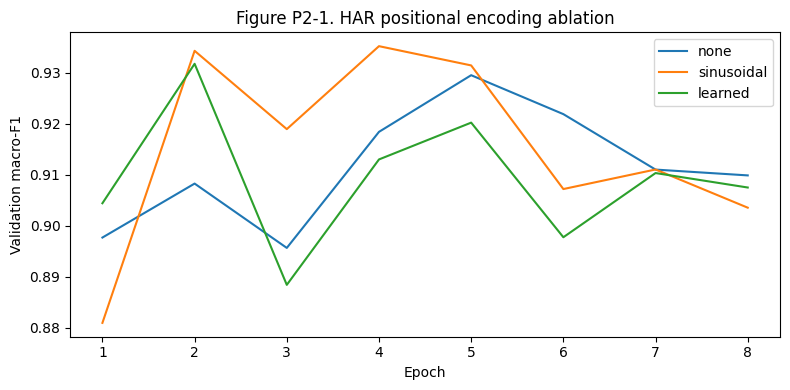

In [8]:
# Run the three positional ablations across all three seeds
har_records=[];har_hist={};best_har=None;best_val=-1
for pos in ['none','sinusoidal','learned']:
 for seed in SEEDS:
  set_seed(seed);tr,va,te=har_split(seed)
  model=HARTransformer(pos=pos)
  model,hist,sec,val_f1=train_classifier(model,tr,va)
  m=eval_classifier(model,te)
  row=dict(problem='P2_HAR',model=f'Transformer_{pos}',seed=seed,seq_len=128,test_acc=m['acc'],macro_f1=m['f1'],params=params(model),sec_per_epoch=sec,notes=f'epochs={HAR_EPOCHS};val_f1={val_f1:.6f}')
  record(**row);har_records.append(row);har_hist[(pos,seed)]=hist
  if val_f1>best_val:best_val=val_f1;best_har=copy.deepcopy(model).cpu();best_pos=pos;best_seed=seed
har_df=pd.DataFrame(har_records)
print(har_df.groupby('model')[['test_acc','macro_f1','params','sec_per_epoch']].agg(['mean','std']))
fig,ax=plt.subplots(figsize=(8,4))
for pos in ['none','sinusoidal','learned']:
 a=np.array([har_hist[(pos,s)] for s in SEEDS]);ax.plot(np.arange(1,HAR_EPOCHS+1),a[:,:,1].mean(0),label=pos)
ax.set(xlabel='Epoch',ylabel='Validation macro-F1',title='Figure P2-1. HAR positional encoding ablation');ax.legend();fig.tight_layout();fig.savefig(FIG/'har_position_ablation.png',dpi=160);plt.show()

## Comparison with Problem 1 (same HAR test set)

The following cell uses the **nine HAR runs from the uploaded Problem 1 `results.csv`** (three recurrent models × three seeds). It compares their sample mean and sample standard deviation with the nine Transformer runs produced above. The best recurrent family is shown descriptively by mean **test** macro-F1; this is *not* a validation-selected checkpoint, so do not describe it as one. Training seconds per epoch are hardware-dependent, and the recurrent and Transformer architectures differ in size. No combined training or shared notebook runtime is necessary.


HAR comparison: mean ± sample SD across the same three seeds
                 family                  model  accuracy_mean  accuracy_sd  f1_mean  f1_sd  parameters  seconds_per_epoch
  Problem 1 — recurrent                    GRU         0.8807       0.0014   0.8806 0.0014  14790.0000             0.1864
  Problem 1 — recurrent                   LSTM         0.8478       0.0133   0.8468 0.0139  19590.0000             0.1772
  Problem 1 — recurrent                    RNN         0.6408       0.0737   0.6068 0.0975   5190.0000             0.1839
Problem 2 — Transformer    Transformer_learned         0.8823       0.0207   0.8805 0.0214 415494.0000             1.8964
Problem 2 — Transformer       Transformer_none         0.8835       0.0146   0.8819 0.0157 398982.0000             1.9256
Problem 2 — Transformer Transformer_sinusoidal         0.8862       0.0125   0.8851 0.0123 398982.0000             1.8333
Best P1 family by mean TEST macro-F1: GRU (0.8806)
Best P2 positional variant by mean

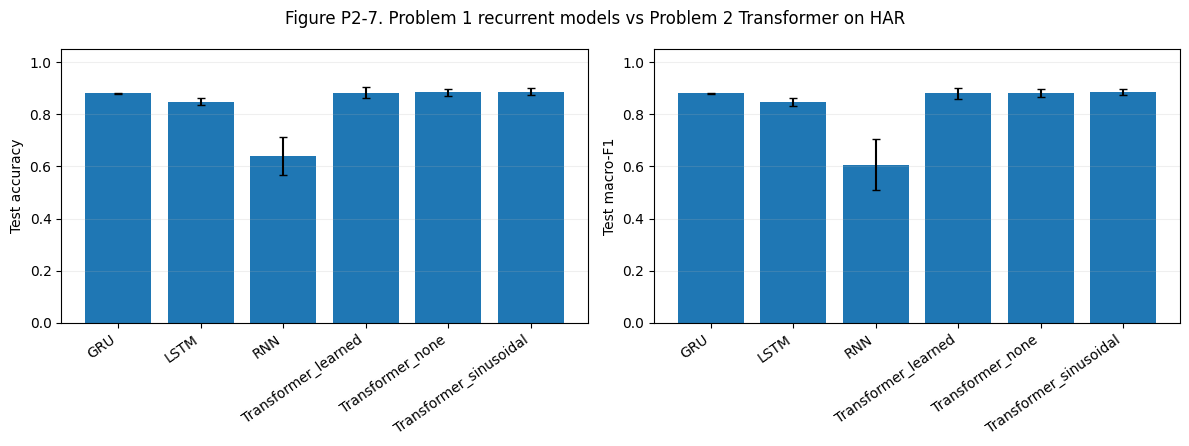

In [9]:
# Reproducible Problem 1 HAR reference: extracted from the user's uploaded results.csv
# Source: 9 P1_HAR rows, seeds 42, 123 and 2026. No manual metric estimates.
P1_HAR_ROWS = [{'problem': 'P1_HAR', 'model': 'RNN', 'seed': 42, 'seq_len': 128, 'test_acc': 0.5561588055649813, 'macro_f1': 0.494268124622562, 'params': 5190, 'sec_per_epoch': 0.2451623453750038}, {'problem': 'P1_HAR', 'model': 'RNN', 'seed': 123, 'seq_len': 128, 'test_acc': 0.6749236511706821, 'macro_f1': 0.6597465575232141, 'params': 5190, 'sec_per_epoch': 0.1525516235000026}, {'problem': 'P1_HAR', 'model': 'RNN', 'seed': 2026, 'seq_len': 128, 'test_acc': 0.6912114014251781, 'macro_f1': 0.6664785435579111, 'params': 5190, 'sec_per_epoch': 0.153891090124997}, {'problem': 'P1_HAR', 'model': 'LSTM', 'seed': 42, 'seq_len': 128, 'test_acc': 0.842551747539871, 'macro_f1': 0.840222258411877, 'params': 19590, 'sec_per_epoch': 0.1715124996249954}, {'problem': 'P1_HAR', 'model': 'LSTM', 'seed': 123, 'seq_len': 128, 'test_acc': 0.837801153715643, 'macro_f1': 0.8374270348362544, 'params': 19590, 'sec_per_epoch': 0.1666155373750015}, {'problem': 'P1_HAR', 'model': 'LSTM', 'seed': 2026, 'seq_len': 128, 'test_acc': 0.8629114353579912, 'macro_f1': 0.8627398444105555, 'params': 19590, 'sec_per_epoch': 0.1934103797500057}, {'problem': 'P1_HAR', 'model': 'GRU', 'seed': 42, 'seq_len': 128, 'test_acc': 0.8819138106549033, 'macro_f1': 0.8818671556242755, 'params': 14790, 'sec_per_epoch': 0.2293637453750037}, {'problem': 'P1_HAR', 'model': 'GRU', 'seed': 123, 'seq_len': 128, 'test_acc': 0.8808958262639973, 'macro_f1': 0.8808629859389355, 'params': 14790, 'sec_per_epoch': 0.1723322576249941}, {'problem': 'P1_HAR', 'model': 'GRU', 'seed': 2026, 'seq_len': 128, 'test_acc': 0.8791991856124872, 'macro_f1': 0.8790194638640102, 'params': 14790, 'sec_per_epoch': 0.1575764484999879}]
p1_har_df = pd.DataFrame(P1_HAR_ROWS)
assert len(p1_har_df)==9 and set(p1_har_df.model)=={'RNN','LSTM','GRU'}
assert set(p1_har_df.seed)==set(SEEDS)
assert len(har_df)==9 and set(har_df.seed)==set(SEEDS)
assert set(p1_har_df.seq_len)=={128} and set(har_df.seq_len)=={128}

p1_summary = p1_har_df.groupby('model').agg(
    accuracy_mean=('test_acc','mean'),accuracy_sd=('test_acc','std'),
    f1_mean=('macro_f1','mean'),f1_sd=('macro_f1','std'),
    parameters=('params','mean'),seconds_per_epoch=('sec_per_epoch','mean')).reset_index()
p1_summary['family']='Problem 1 — recurrent'
p2_summary = har_df.groupby('model').agg(
    accuracy_mean=('test_acc','mean'),accuracy_sd=('test_acc','std'),
    f1_mean=('macro_f1','mean'),f1_sd=('macro_f1','std'),
    parameters=('params','mean'),seconds_per_epoch=('sec_per_epoch','mean')).reset_index()
p2_summary['family']='Problem 2 — Transformer'
comparison_df = pd.concat([p1_summary,p2_summary],ignore_index=True)
comparison_df = comparison_df[['family','model','accuracy_mean','accuracy_sd','f1_mean','f1_sd','parameters','seconds_per_epoch']]
comparison_df.to_csv(ROOT/'problem1_vs_problem2_har_comparison.csv',index=False)
p1_har_df.to_csv(ROOT/'problem1_har_source_rows.csv',index=False)
print('HAR comparison: mean ± sample SD across the same three seeds')
print(comparison_df.to_string(index=False,float_format=lambda x:f'{x:.4f}'))
best_p1 = p1_summary.sort_values('f1_mean',ascending=False).iloc[0]
best_p2 = p2_summary.sort_values('f1_mean',ascending=False).iloc[0]
print(f"Best P1 family by mean TEST macro-F1: {best_p1['model']} ({best_p1['f1_mean']:.4f})")
print(f"Best P2 positional variant by mean TEST macro-F1: {best_p2['model']} ({best_p2['f1_mean']:.4f})")
print(f"Difference P2 minus P1: accuracy={best_p2['accuracy_mean']-best_p1['accuracy_mean']:+.4f}; "
      f"macro-F1={best_p2['f1_mean']-best_p1['f1_mean']:+.4f}")
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
for ax,metric,sd,label in [(axes[0],'accuracy_mean','accuracy_sd','Test accuracy'),
                            (axes[1],'f1_mean','f1_sd','Test macro-F1')]:
    x=np.arange(len(comparison_df));ax.bar(x,comparison_df[metric],yerr=comparison_df[sd],capsize=3)
    ax.set_xticks(x,comparison_df.model,rotation=35,ha='right');ax.set_ylabel(label)
    ax.set_ylim(0,1.05);ax.grid(axis='y',alpha=.2)
fig.suptitle('Figure P2-7. Problem 1 recurrent models vs Problem 2 Transformer on HAR')
fig.tight_layout();fig.savefig(FIG/'p1_vs_p2_har.png',dpi=160,bbox_inches='tight');plt.show()


## Task 4 — Tiny Shakespeare character-level causal language model

In [10]:
# Download Tiny Shakespeare and create chronological 90/10 splits
text=urllib.request.urlopen('https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt').read().decode('utf-8')
chars=sorted(set(text));stoi={c:i for i,c in enumerate(chars)};itos={i:c for c,i in stoi.items()}
encoded=torch.tensor([stoi[c] for c in text],dtype=torch.long)
split=int(.9*len(encoded));train_ids=encoded[:split];val_ids=encoded[split:]
VOCAB=len(chars);print('Characters:',len(text),'Vocabulary:',VOCAB,'train/val:',len(train_ids),len(val_ids))
assert VOCAB==65
def batch_tokens(ids,context=LM_CONTEXT,batch=LM_BATCH):
 starts=torch.randint(0,len(ids)-context-1,(batch,))
 x=torch.stack([ids[i:i+context] for i in starts]);y=torch.stack([ids[i+1:i+context+1] for i in starts])
 return x.to(DEVICE),y.to(DEVICE)

Characters: 1115394 Vocabulary: 65 train/val: 1003854 111540


In [11]:
# Define a causal character language model around the custom encoder blocks
class CharTransformer(nn.Module):
 def __init__(self,d=D,heads=HEADS,layers=LM_LAYERS,context=LM_CONTEXT,causal=True):
  super().__init__();self.context=context;self.causal=causal
  self.embed=nn.Embedding(VOCAB,d);self.pos=nn.Embedding(context,d)
  self.blocks=nn.ModuleList([MyEncoderBlock(d,heads) for _ in range(layers)])
  self.norm=nn.LayerNorm(d);self.head=nn.Linear(d,VOCAB)
 def forward(self,idx,return_weights=False):
  b,t=idx.shape;assert t<=self.context
  x=self.embed(idx)+self.pos(torch.arange(t,device=idx.device))[None]
  mask=torch.ones(t,t,dtype=torch.bool,device=idx.device).tril() if self.causal else None
  weights=[]
  for block in self.blocks:
   x,w=block(x,mask=mask);weights.append(w)
  logits=self.head(self.norm(x))
  return (logits,weights) if return_weights else logits
@torch.no_grad()
def lm_loss(model,ids,context=LM_CONTEXT,batches=15):
 model.eval();losses=[]
 for _ in range(batches):
  x,y=batch_tokens(ids,context);z=model(x);losses.append(F.cross_entropy(z.reshape(-1,VOCAB),y.reshape(-1)).item())
 return float(np.mean(losses))
def train_lm(model,steps=LM_STEPS,context=LM_CONTEXT):
 model.to(DEVICE);opt=torch.optim.AdamW(model.parameters(),lr=3e-4);hist=[];t0=time.perf_counter()
 for step in range(1,steps+1):
  model.train();x,y=batch_tokens(train_ids,context)
  opt.zero_grad(set_to_none=True);z=model(x)
  loss=F.cross_entropy(z.reshape(-1,VOCAB),y.reshape(-1));loss.backward();torch.nn.utils.clip_grad_norm_(model.parameters(),1);opt.step()
  if step==1 or step%100==0 or step==steps:
   vl=lm_loss(model,val_ids,context);hist.append((step,loss.item(),vl));print(f'step {step}/{steps} train={loss.item():.3f} val={vl:.3f}')
 return model,hist,(time.perf_counter()-t0)/steps
@torch.no_grad()
def generate(model,temperature=0.8,k=40,length=500,prefix='ROMEO:'):
 model.eval();ids=torch.tensor([[stoi[c] for c in prefix]],device=DEVICE)
 for _ in range(length):
  logits=model(ids[:,-model.context:])[:,-1]/temperature
  values,indices=torch.topk(logits,min(k,logits.size(-1)),dim=-1)
  probs=F.softmax(values,dim=-1);choice=indices.gather(-1,torch.multinomial(probs,1))
  ids=torch.cat([ids,choice],dim=1)
 return ''.join(itos[int(i)] for i in ids[0,-length:].cpu())
print('Language-model helpers ready')

Language-model helpers ready


step 1/1000 train=4.319 val=4.187
step 100/1000 train=2.652 val=2.637
step 200/1000 train=2.508 val=2.521
step 300/1000 train=2.486 val=2.472
step 400/1000 train=2.440 val=2.450
step 500/1000 train=2.433 val=2.394
step 600/1000 train=2.375 val=2.339
step 700/1000 train=2.320 val=2.271
step 800/1000 train=2.288 val=2.235
step 900/1000 train=2.174 val=2.185
step 1000/1000 train=2.150 val=2.153
Validation loss (nats): 2.1544128894805907 bits/character: 3.108160791680911


/tmp/ipykernel_36688/2934540826.py:22: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  pd.concat([old,pd.DataFrame([row])],ignore_index=True).to_csv(RESULTS,index=False)


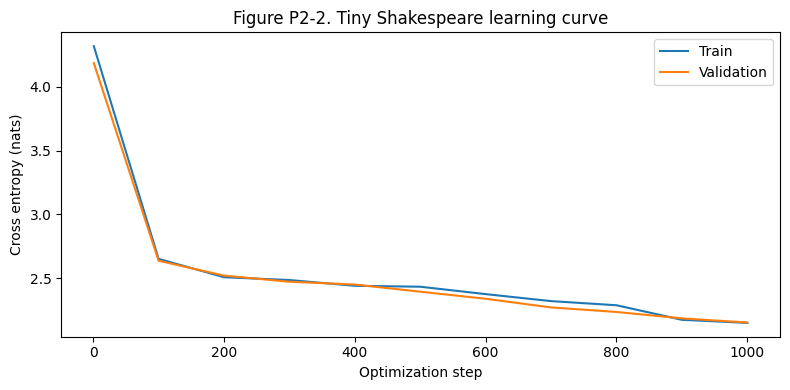


Temperature 0.2:

I the the the the mat the hee the the the the the so mat
This the the so the the the beat stere the the the ber the the seat the theat s
The the beat the so the wis the the the beat the the sheat my
The ther she the thee she then the thee and the my...

Temperature 0.8:

As, thas I sur dowll not dot man,
Hast salle thin it falim my in sward Cowin thee feaveds sellig.

ONCESAR:
Wer sill? do Enor Ror my excond and cond,
Imod bee wis rusow as the o thind the lim pe!

Vhirr ROwirt If your ben withe wisse not om thown hi...

Temperature 1.5:

Wefe.

ALO:? hutinins, ho; hiv, sthegBe't t'ee fore, poolf:
Thisster:
Omclirasd qot oldin co hisr, s tre wis;
SyowShowe you pisvak squch eereerlis sedfaiur'y,
Bet uryfos not asess of ort
TheeNes, tatu igky avef hall
Toug in scay proabemow she gores ...


In [12]:
# Train the four-layer causal Transformer and export three 500-character samples
set_seed(SEEDS[0]);trained_lm=CharTransformer()
trained_lm,lm_history,sec_per_step=train_lm(trained_lm)
val_nats=lm_loss(trained_lm,val_ids);bpc=val_nats/math.log(2)
record(problem='P2_LM',model='causal_transformer',seed=SEEDS[0],seq_len=LM_CONTEXT,params=params(trained_lm),sec_per_epoch=sec_per_step*LM_STEPS,val_loss_nats=val_nats,bits_per_char=bpc,notes=f'steps={LM_STEPS};heads={HEADS};layers={LM_LAYERS}')
print('Validation loss (nats):',val_nats,'bits/character:',bpc)
samples={t:generate(trained_lm,t,40,500) for t in [0.2,0.8,1.5]}
(ROOT/'generated_samples.txt').write_text('\n\n'.join(f'Temperature {t}:\n{s}' for t,s in samples.items()),encoding='utf-8')
fig,ax=plt.subplots(figsize=(8,4));a=np.array(lm_history);ax.plot(a[:,0],a[:,1],label='Train');ax.plot(a[:,0],a[:,2],label='Validation');ax.set(xlabel='Optimization step',ylabel='Cross entropy (nats)',title='Figure P2-2. Tiny Shakespeare learning curve');ax.legend();fig.tight_layout();fig.savefig(FIG/'shakespeare_learning_curve.png',dpi=160);plt.show()
for t,s in samples.items():print(f'\nTemperature {t}:\n{s[:250]}...')

## Task 5 — Attention heatmaps, head-count ablation, causal-mask ablation, and context benchmarking

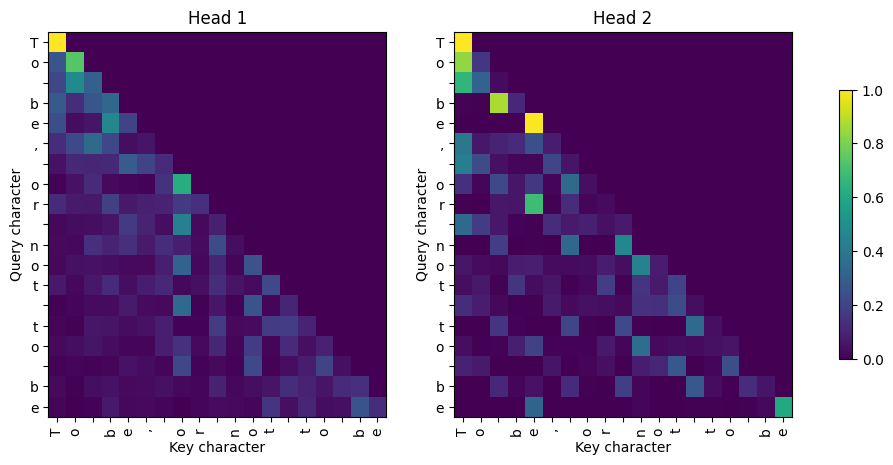

In [13]:
# Visualize two attention heads on a fixed Shakespeare character sequence
sample='To be, or not to be'
idx=torch.tensor([[stoi[c] for c in sample]],device=DEVICE)
trained_lm.eval()
with torch.no_grad():_,weights=trained_lm(idx,return_weights=True)
w=weights[-1][0].detach().cpu().numpy()
fig,axes=plt.subplots(1,2,figsize=(12,5))
for i,ax in enumerate(axes):
 im=ax.imshow(w[i],aspect='auto',vmin=0,vmax=1);ax.set(title=f'Head {i+1}',xlabel='Key character',ylabel='Query character');ax.set_xticks(range(len(sample)),list(sample),rotation=90);ax.set_yticks(range(len(sample)),list(sample))
fig.colorbar(im,ax=axes.ravel().tolist(),shrink=.7);fig.savefig(FIG/'two_attention_heads.png',dpi=160,bbox_inches='tight');plt.show()

step 1/300 train=4.319 val=4.186
step 100/300 train=2.648 val=2.631
step 200/300 train=2.505 val=2.515
step 300/300 train=2.470 val=2.461


/tmp/ipykernel_36688/2934540826.py:22: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  pd.concat([old,pd.DataFrame([row])],ignore_index=True).to_csv(RESULTS,index=False)


step 1/300 train=4.319 val=4.187
step 100/300 train=2.652 val=2.637
step 200/300 train=2.508 val=2.521
step 300/300 train=2.486 val=2.472


/tmp/ipykernel_36688/2934540826.py:22: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  pd.concat([old,pd.DataFrame([row])],ignore_index=True).to_csv(RESULTS,index=False)


step 1/300 train=4.320 val=4.187
step 100/300 train=2.654 val=2.640
step 200/300 train=2.508 val=2.522
step 300/300 train=2.485 val=2.474
     model  val_loss_nats  params
0  heads_1       2.460468  826433
1  heads_4       2.473038  826433
2  heads_8       2.475163  826433


/tmp/ipykernel_36688/2934540826.py:22: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  pd.concat([old,pd.DataFrame([row])],ignore_index=True).to_csv(RESULTS,index=False)


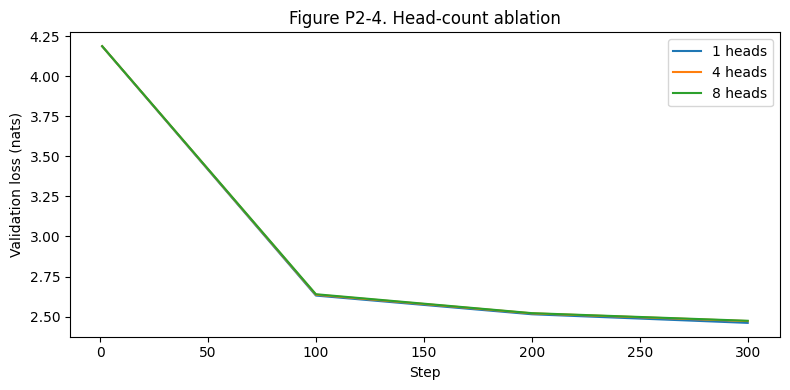

In [14]:
# Compare one, four and eight heads at the same model width
HEAD_ABLATION_STEPS=300
head_rows=[];head_curves={}
for h in [1,4,8]:
 set_seed(SEEDS[0]);model=CharTransformer(heads=h)
 model,hist,seconds=train_lm(model,steps=HEAD_ABLATION_STEPS)
 vl=lm_loss(model,val_ids);row=dict(problem='P2_heads',model=f'heads_{h}',seed=SEEDS[0],seq_len=LM_CONTEXT,params=params(model),sec_per_epoch=seconds*HEAD_ABLATION_STEPS,val_loss_nats=vl,bits_per_char=vl/math.log(2),notes=f'steps={HEAD_ABLATION_STEPS}')
 record(**row);head_rows.append(row);head_curves[h]=hist
head_df=pd.DataFrame(head_rows);print(head_df[['model','val_loss_nats','params']])
fig,ax=plt.subplots(figsize=(8,4))
for h,hist in head_curves.items():
 a=np.array(hist);ax.plot(a[:,0],a[:,2],label=f'{h} heads')
ax.set(xlabel='Step',ylabel='Validation loss (nats)',title='Figure P2-4. Head-count ablation');ax.legend();fig.tight_layout();fig.savefig(FIG/'head_ablation.png',dpi=160);plt.show()

step 1/300 train=4.319 val=4.187
step 100/300 train=2.652 val=2.637
step 200/300 train=2.508 val=2.521
step 300/300 train=2.486 val=2.472


/tmp/ipykernel_36688/2934540826.py:22: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  pd.concat([old,pd.DataFrame([row])],ignore_index=True).to_csv(RESULTS,index=False)


step 1/300 train=4.319 val=4.189
step 100/300 train=2.652 val=2.639
step 200/300 train=2.498 val=2.520
step 300/300 train=2.474 val=2.461


/tmp/ipykernel_36688/2934540826.py:22: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  pd.concat([old,pd.DataFrame([row])],ignore_index=True).to_csv(RESULTS,index=False)


     model  val_loss_nats
0   causal       2.473038
1  no_mask       2.460277
No-mask sample: 
LINCACRICELUCBR:
A
H:

GRIS:

ELOYUS:
LUCLENMRRq:

TOLOCIUGQLGLUS:
MENGOS:
K:
HLLOEOI:
B:
TISLINGENEMEREDLLGELIO

G

S:
FUC


BREAR

LE-
BSKU&P:
SOLOUL: I:

DFUTIUS:

CUMIAR$, VENTETINO:


YULIO's FORDI:
O?

USCNERD
:
WINEOV:
LONouMUS:




VLOLEUMAK:
xE:



LUCOLAROM:
B:

TUOULULLORL



DUPUD'US:




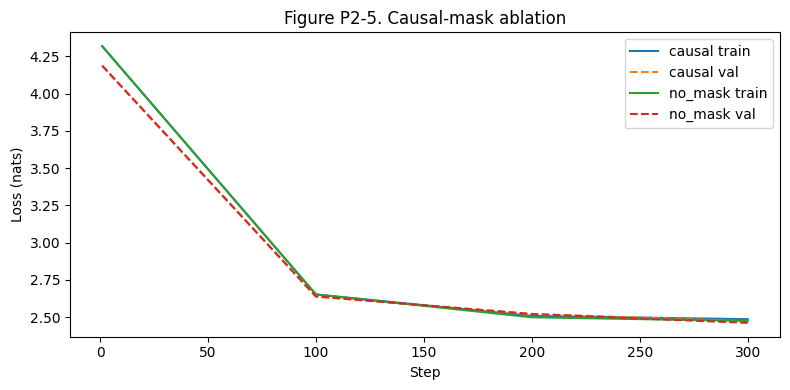

In [15]:
# Compare causal masking against an otherwise identical noncausal model
MASK_STEPS=300;mask_rows=[];mask_curves={};mask_samples={}
for causal in [True,False]:
 set_seed(SEEDS[0]);model=CharTransformer(causal=causal)
 model,hist,seconds=train_lm(model,steps=MASK_STEPS)
 vl=lm_loss(model,val_ids);label='causal' if causal else 'no_mask'
 mask_samples[label]=generate(model,0.8,40,500)
 row=dict(problem='P2_mask',model=label,seed=SEEDS[0],seq_len=LM_CONTEXT,params=params(model),sec_per_epoch=seconds*MASK_STEPS,val_loss_nats=vl,bits_per_char=vl/math.log(2),notes=f'steps={MASK_STEPS}')
 record(**row);mask_rows.append(row);mask_curves[label]=hist
print(pd.DataFrame(mask_rows)[['model','val_loss_nats']]);print('No-mask sample:',mask_samples['no_mask'][:300])
fig,ax=plt.subplots(figsize=(8,4))
for label,hist in mask_curves.items():
 a=np.array(hist);ax.plot(a[:,0],a[:,1],label=f'{label} train');ax.plot(a[:,0],a[:,2],ls='--',label=f'{label} val')
ax.set(xlabel='Step',ylabel='Loss (nats)',title='Figure P2-5. Causal-mask ablation');ax.legend();fig.tight_layout();fig.savefig(FIG/'causal_mask_ablation.png',dpi=160);plt.show()

{'context': 64, 'ms_per_forward': 3.553462300078536, 'peak_cuda_mb': 0.62890625}
{'context': 128, 'ms_per_forward': 3.487004899943713, 'peak_cuda_mb': 1.765625}
{'context': 256, 'ms_per_forward': 3.702369600068778, 'peak_cuda_mb': 5.8125}
{'context': 512, 'ms_per_forward': 3.3829813999545877, 'peak_cuda_mb': 21.75}


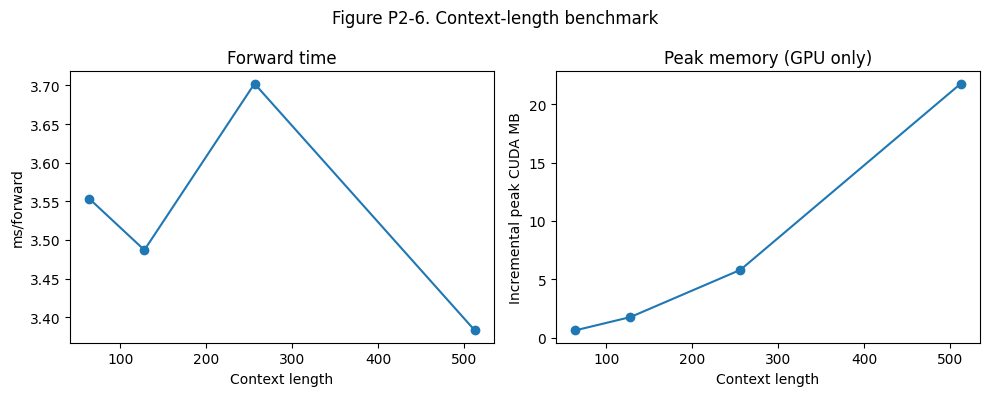

In [16]:
# Benchmark identical trained weights at four context lengths; vary only input length.
# Expand learned positional embeddings for evaluation without changing Transformer blocks.
import copy
bench_model = copy.deepcopy(trained_lm).to(DEVICE)
old_position = bench_model.pos.weight.detach().clone()
bench_model.context = 512
bench_model.pos = nn.Embedding(512, D).to(DEVICE)
with torch.no_grad():
    bench_model.pos.weight[:old_position.shape[0]].copy_(old_position)
    bench_model.pos.weight[old_position.shape[0]:].copy_(old_position[-1])
bench_model.eval()
bench = []
for length in [64,128,256,512]:
    x = torch.randint(0, VOCAB, (1,length), device=DEVICE)
    with torch.no_grad():
        for _ in range(3): bench_model(x)
        if DEVICE.type == 'cuda':
            torch.cuda.synchronize()
            torch.cuda.reset_peak_memory_stats()
            base_memory = torch.cuda.memory_allocated()
        t0 = time.perf_counter()
        for _ in range(10): bench_model(x)
        if DEVICE.type == 'cuda': torch.cuda.synchronize()
        ms = (time.perf_counter()-t0)*1000/10
        memory = ((torch.cuda.max_memory_allocated()-base_memory)/1024**2
                  if DEVICE.type == 'cuda' else float('nan'))
    bench.append(dict(context=length,ms_per_forward=ms,peak_cuda_mb=memory))
    print(bench[-1])
bench_df=pd.DataFrame(bench);bench_df.to_csv(ROOT/'context_benchmark.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(10,4))
axes[0].plot(bench_df.context,bench_df.ms_per_forward,'o-')
axes[0].set(xlabel='Context length',ylabel='ms/forward',title='Forward time')
axes[1].plot(bench_df.context,bench_df.peak_cuda_mb,'o-')
axes[1].set(xlabel='Context length',ylabel='Incremental peak CUDA MB',title='Peak memory (GPU only)')
fig.suptitle('Figure P2-6. Context-length benchmark')
fig.tight_layout();fig.savefig(FIG/'context_time_memory.png',dpi=160);plt.show()


## Task 5 — Measured interpretations and limitations

The analysis cell below writes evidence-based observations from the computed attention matrices, head-count ablation, causal-mask ablation, context benchmark and the embedded Problem 1 HAR results. These are descriptive measurements, not claims of statistical significance. Attention concentration does not by itself establish a linguistic interpretation; the plotted heads should also be visually inspected; generated notes provide prompt-specific interpretations for both heads. The context-length memory benchmark is GPU-only and its positional embeddings beyond length 128 are extended for measurement rather than retrained, so lengths 256 and 512 benchmark compute/memory only, not language-model quality.


In [17]:
# Create measured analysis notes, including automatic attention-head diagnostics.
summary=[]
summary.append('PROBLEM 2 — RESULTS AND MEASURED INTERPRETATION')
summary.append('HAR positional variants (mean ± sample SD over 3 seeds):')
for name,group in har_df.groupby('model'):
    summary.append(f"{name}: accuracy={group.test_acc.mean():.4f} ± {group.test_acc.std(ddof=1):.4f}; "
                   f"macro-F1={group.macro_f1.mean():.4f} ± {group.macro_f1.std(ddof=1):.4f}; "
                   f"parameters={int(group.params.iloc[0])}; seconds/epoch={group.sec_per_epoch.mean():.3f}")
summary.append(f'Best P2 checkpoint selected by VALIDATION macro-F1: {best_pos}, seed {best_seed}')
summary.append('PROBLEM 1 vs PROBLEM 2 — same HAR test set, 3 common seeds:')
for _,r in comparison_df.iterrows():
    summary.append(f"{r['family']} {r['model']}: accuracy {r['accuracy_mean']:.4f} ± {r['accuracy_sd']:.4f}, "
                   f"macro-F1 {r['f1_mean']:.4f} ± {r['f1_sd']:.4f}, parameters {r['parameters']:.0f}, "
                   f"seconds/epoch {r['seconds_per_epoch']:.3f}")
summary.append(f"Highest P1 mean TEST F1: {best_p1['model']} ({best_p1['f1_mean']:.4f}); "
               f"highest P2 mean TEST F1: {best_p2['model']} ({best_p2['f1_mean']:.4f}); "
               f"difference P2−P1={best_p2['f1_mean']-best_p1['f1_mean']:+.4f}.")
summary.append('Caution: selecting model families using test results is descriptive, not validation-based model selection.')
summary.append(f'Tiny Shakespeare causal LM: validation loss {val_nats:.4f} nats, '
               f'{bpc:.4f} bits/character, parameters {params(trained_lm)}.')
summary.append('TEMPERATURE COMPARISON — generated 500-character samples with top-k sampling:')
# Report observable diversity/repetition from the actual generated samples, not just expected trends.
for temp in [0.2,0.8,1.5]:
    generated = samples[temp]
    unique_ratio = len(set(generated)) / len(generated)
    repeated_trigrams = sum(generated[i:i+3] == generated[i-3:i] for i in range(3,len(generated)-2))
    word_count = len(generated.split())
    summary.append(f'T={temp}: {len(generated)} characters, {len(set(generated))} unique characters '
                   f'({unique_ratio:.1%} unique-character ratio), {repeated_trigrams} immediate '
                   f'repeated trigrams, {word_count} whitespace-separated words.')
summary.append('Interpretation: Low temperature (0.2) sharpens high-probability choices and often repeats '
               'common patterns; moderate temperature (0.8) balances variety and local coherence; '
               'high temperature (1.5) increases less-likely choices and may produce more erratic text. '
               'These are sampling expectations, not automatic proof of coherence: read the three '
               'saved samples and describe any exceptions based on their actual wording.')
summary.append('TWO ATTENTION HEADS — last LM layer, fixed prompt: '+repr(sample))
for hi in [0,1]:
    mat=w[hi]; n=mat.shape[0]
    diag=float(np.diag(mat).mean())
    prev=float(np.mean([mat[t,t-1] for t in range(1,n)]))
    first=float(mat[:,0].mean())
    entropy=float((-mat*np.log(np.maximum(mat,1e-12))).sum(axis=-1).mean())
    # Most-attended key for the final query position, from actual plotted matrix.
    strongest=int(np.argmax(mat[-1]))
    summary.append(f'Head {hi+1}: mean diagonal attention {diag:.3f}, '
                   f'mean previous-character attention {prev:.3f}, '
                   f'mean first-character attention {first:.3f}, entropy {entropy:.3f} nats; '
                   f'final query most attends to key position {strongest} (character {sample[strongest]!r}).')
# Describe each head's measured pattern, without attributing an unverified linguistic role.
for hi in [0,1]:
    mat = w[hi]
    n = mat.shape[0]
    diagonal = float(np.diag(mat).mean())
    previous = float(np.mean([mat[t,t-1] for t in range(1,n)]))
    first = float(mat[:,0].mean())
    # For each query, identify its strongest permitted key (including self).
    winners = np.argmax(mat,axis=-1)
    self_fraction = float(np.mean(winners == np.arange(n)))
    first_fraction = float(np.mean(winners == 0))
    if self_fraction >= 0.5:
        pattern = 'often places its strongest weight on the current character'
    elif first_fraction >= 0.5:
        pattern = 'often places its strongest weight on the first character of the prompt'
    elif previous > diagonal and previous > first:
        pattern = 'on average weights the preceding character more than the current or first character'
    elif diagonal >= previous and diagonal >= first:
        pattern = 'on average favors the current character relative to the preceding or first character'
    else:
        pattern = 'distributes attention across several earlier character positions'
    summary.append(f'Head {hi+1} interpretation: On this fixed prompt, the head {pattern}; '
                   f'{self_fraction:.0%} of query rows have their maximum at self and '
                   f'{first_fraction:.0%} at the first token. This describes this example only, '
                   'not a proven linguistic specialization.')
summary.append('Attention heatmaps visualize these two heads in the last LM layer; interpretation is limited to the displayed prompt.')
summary.append('HEAD COUNT ABLATION — same width, 300 steps:')
for r in head_rows:
    summary.append(f"{r['model']}: validation {r['val_loss_nats']:.4f} nats, parameters {r['params']}")
head_best=min(head_rows,key=lambda r:r['val_loss_nats'])
summary.append(f"Lowest measured validation loss: {head_best['model']}; compare curves before inferring any consistent advantage.")
summary.append('CAUSAL MASK ABLATION — same training budget:')
for r in mask_rows:
    summary.append(f"{r['model']}: validation {r['val_loss_nats']:.4f} nats")
summary.append('Removing the causal mask allows a query to see future positions (including its next-token label), '
               'so unmasked next-token losses are leaked and cannot be interpreted as autoregressive performance. '
               'The no-mask generation sample is therefore not a valid causal language-model sample.')
summary.append('CONTEXT LENGTH BENCHMARK — forward pass, same weights:')
for r in bench:
    summary.append(f"T={r['context']}: {r['ms_per_forward']:.3f} ms/forward, "
                   f"incremental GPU peak={r['peak_cuda_mb']:.3f} MiB")
ratio=bench[-1]['ms_per_forward']/bench[0]['ms_per_forward']
summary.append(f'Observed time ratio T=512 / T=64: {ratio:.2f}x. '
               'Theoretical attention-score element ratio is (512/64)^2 = 64x per head/layer; '
               'total wall time need not scale by 64x due to other operations and hardware effects.')
if DEVICE.type!='cuda':summary.append('CPU runtime: GPU peak-memory numbers are unavailable (NaN).')
else:summary.append('Peak CUDA memory is measured incrementally relative to baseline allocated memory, not total model footprint.')
summary.append('Limits: single seed for LM ablations and 300 optimization steps. Positions 129–512 use repeated last-position embeddings only for forward-pass scaling measurements; the model was trained with context 128. Thus the 256/512 benchmarks do NOT measure trained-context predictive quality or valid longer-context perplexity.')
(ROOT/'analysis_notes.txt').write_text('\n'.join(summary),encoding='utf-8')
print('\n'.join(summary))


PROBLEM 2 — RESULTS AND MEASURED INTERPRETATION
HAR positional variants (mean ± sample SD over 3 seeds):
Transformer_learned: accuracy=0.8823 ± 0.0207; macro-F1=0.8805 ± 0.0214; parameters=415494; seconds/epoch=1.896
Transformer_none: accuracy=0.8835 ± 0.0146; macro-F1=0.8819 ± 0.0157; parameters=398982; seconds/epoch=1.926
Transformer_sinusoidal: accuracy=0.8862 ± 0.0125; macro-F1=0.8851 ± 0.0123; parameters=398982; seconds/epoch=1.833
Best P2 checkpoint selected by VALIDATION macro-F1: sinusoidal, seed 123
PROBLEM 1 vs PROBLEM 2 — same HAR test set, 3 common seeds:
Problem 1 — recurrent GRU: accuracy 0.8807 ± 0.0014, macro-F1 0.8806 ± 0.0014, parameters 14790, seconds/epoch 0.186
Problem 1 — recurrent LSTM: accuracy 0.8478 ± 0.0133, macro-F1 0.8468 ± 0.0139, parameters 19590, seconds/epoch 0.177
Problem 1 — recurrent RNN: accuracy 0.6408 ± 0.0737, macro-F1 0.6068 ± 0.0975, parameters 5190, seconds/epoch 0.184
Problem 2 — Transformer Transformer_learned: accuracy 0.8823 ± 0.0207, macr

In [18]:
# Final coverage and output checks: run only after all preceding experiments.
required=['har_position_ablation.png','shakespeare_learning_curve.png','two_attention_heads.png',
          'head_ablation.png','causal_mask_ablation.png','context_time_memory.png','p1_vs_p2_har.png']
for f in required:assert (FIG/f).is_file(),f'Missing figure: {f}'
for f in ['generated_samples.txt','analysis_notes.txt','context_benchmark.csv',
          'problem1_vs_problem2_har_comparison.csv','problem1_har_source_rows.csv']:
    assert (ROOT/f).is_file(),f'Missing output: {f}'
assert len(samples)==3 and all(len(s)==500 for s in samples.values())
assert len(har_df)==9 and len(head_df)==3 and len(mask_rows)==2 and len(bench_df)==4
assert len(p1_har_df)==9 and len(comparison_df)==6
all_results=pd.read_csv(RESULTS)
assert list(all_results.columns)==COLUMNS
for name,count in [('P2_HAR',9),('P2_LM',1),('P2_heads',3),('P2_mask',2)]:
    assert (all_results.problem==name).sum()>=count,f'Expected {count} rows for {name}'
assert 'Head 1:' in (ROOT/'analysis_notes.txt').read_text()
assert 'Head 1 interpretation:' in (ROOT/'analysis_notes.txt').read_text()
assert 'Head 2 interpretation:' in (ROOT/'analysis_notes.txt').read_text()
assert 'TEMPERATURE COMPARISON' in (ROOT/'analysis_notes.txt').read_text()
assert 'do NOT measure trained-context predictive quality' in (ROOT/'analysis_notes.txt').read_text()
assert expected_total == params(block)
assert 'PROBLEM 1 vs PROBLEM 2' in (ROOT/'analysis_notes.txt').read_text()
print('PASS: Problem 2 experiments, figures, actual Problem 1 comparison, and measured analysis verified.')
print('Submission artifacts are in problem2/ and results.csv.')


PASS: Problem 2 experiments, figures, actual Problem 1 comparison, and measured analysis verified.
Submission artifacts are in problem2/ and results.csv.


In [19]:
notebook_end = time.perf_counter()
total_seconds = notebook_end - notebook_start

print(f"Total runtime: {total_seconds / 60:.2f} minutes")

Total runtime: 3.64 minutes


In [20]:
from google.colab import files
files.download("results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:
import os
import shutil
from google.colab import files

# Check that the figures folder exists
print(os.listdir("problem2/figures"))

# Create ZIP and download
shutil.make_archive("problem2_figures", "zip", "problem2/figures")
files.download("problem2_figures.zip")

['har_position_ablation.png', 'shakespeare_learning_curve.png', 'causal_mask_ablation.png', 'p1_vs_p2_har.png', 'head_ablation.png', 'two_attention_heads.png', 'context_time_memory.png']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>